# BodyM: CNN hai góc nhìn kết hợp metadata

Hai ảnh silhouette trước/nghiêng dùng **chung CNN 16 → 32 → 64 → 128**, sau đó Global Average Pooling. Metadata (chiều cao, cân nặng, giới tính) đi qua MLP 3 → 32 → 16. Ghép 272 đặc trưng → 128 → 64 → 3 số đo ngực, eo, hông.

Học từ đầu với Huber loss, AdamW và Dropout. Chọn epoch theo validation chia theo người; sau đó khởi tạo lại và refit toàn bộ train trước khi đánh giá test. Dùng đúng danh sách người và cách tính MAE của Ridge.

BatchNorm được hiệu chuẩn lại bằng ảnh train sau mỗi epoch, không cập nhật trọng số và không dùng ảnh validation/test.

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/bodym_cnn.py').exists())
sys.path.insert(0, str(ROOT/'scripts'))
from bodym_cnn import TwoViewBodyCNN, predict_pair
OUTPUT = ROOT/'experiments/bodym_cnn'
config = json.loads((ROOT/'configs/bodym_cnn.json').read_text(encoding='utf-8'))
model = TwoViewBodyCNN(config)
print(model)
print('Parameters:', sum(p.numel() for p in model.parameters()))

TwoViewBodyCNN(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (

In [2]:
# Chọn kernel .venv. Đổi thành True để huấn luyện lại, có thể mất nhiều phút.
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT/'scripts/run_bodym_cnn.py')], cwd=ROOT, check=True)
if not (OUTPUT/'metrics.json').exists():
    raise FileNotFoundError('Run scripts/run_bodym_cnn.py first and wait for training to finish.')
report = json.loads((OUTPUT/'metrics.json').read_text(encoding='utf-8'))
print('Device:', report['device'])
print('Selected epoch:', report['selected_epoch'])
print('Refit subjects:', report['final_train_subjects'])
print('GPU training minutes:', round(report['training_seconds']/60, 1))

Device: NVIDIA GeForce RTX 4060
Selected epoch: 55
Refit subjects: 2018
GPU training minutes: 4.9


# BodyM custom CNN

Two silhouette views share a four-block CNN (16/32/64/128 channels, BatchNorm, ReLU, MaxPool, Global Average Pooling).
Height, weight and sex pass through a 3 -> 32 -> 16 MLP; fusion is 272 -> 128 -> 64 -> 3 with dropout.

Device: NVIDIA GeForce RTX 4060; parameters: 141,443; selected epoch: 55.

The best epoch is selected using the same 1,614/404-subject fit/validation split as Ridge.
The network is then initialized again and trained on all 2,018 train subjects for that many epochs.
Metadata and targets are normalized using only the training subjects of each phase.
BatchNorm statistics are recalibrated using only training images after each epoch at fixed weights.
Huber loss and MAE give each subject equal total weight. TestA and testB remain separate.

| Model | Split | Chest MAE (cm) | Waist MAE (cm) | Hip MAE (cm) | Mean MAE (cm) |
| --- | --- | ---: | ---: | ---: | ---: |
| metadata_ridge | validation | 2.872 | 3.478 | 2.292 | 2.881 |
| metadata_ridge | testA | 2.903 | 3.306 | 2.018 | 2.742 |
| metadata_ridge | testB | 3.277 | 3.561 | 2.446 | 3.095 |
| silhouette_metadata_ridge | validation | 2.236 | 2.788 | 1.957 | 2.327 |
| silhouette_metadata_ridge | testA | 2.284 | 2.613 | 1.840 | 2.246 |
| silhouette_metadata_ridge | testB | 2.952 | 3.719 | 2.399 | 3.023 |
| two_view_cnn | validation | 2.351 | 2.630 | 1.886 | 2.289 |
| two_view_cnn | testA | 2.342 | 2.270 | 1.519 | 2.043 |
| two_view_cnn | testB | 2.797 | 2.944 | 2.186 | 2.642 |





This is one initial run of a custom architecture. Inputs include supplied metadata and binary silhouettes.
Original testA and testB share one subject ID. The model predicts circumferences, not InBody fat/muscle values.


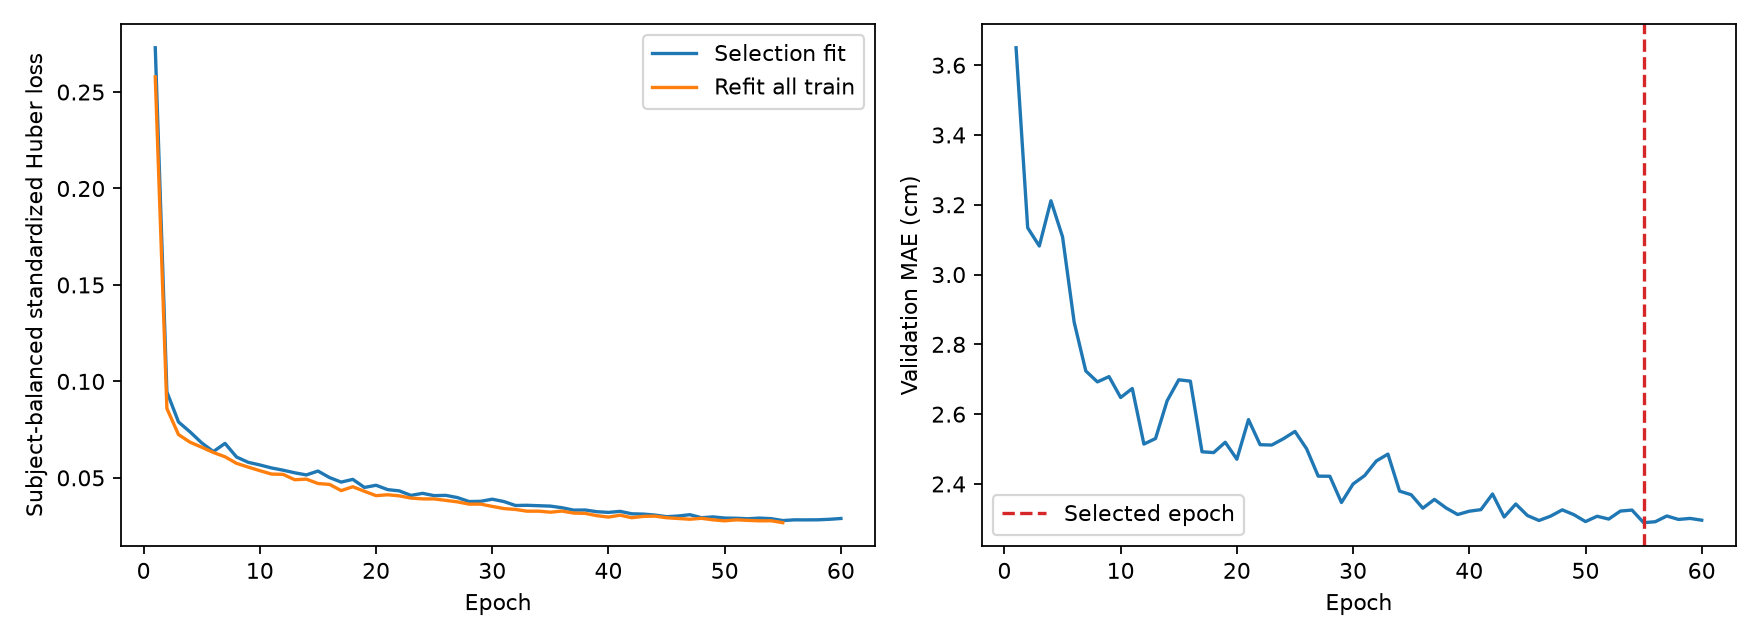

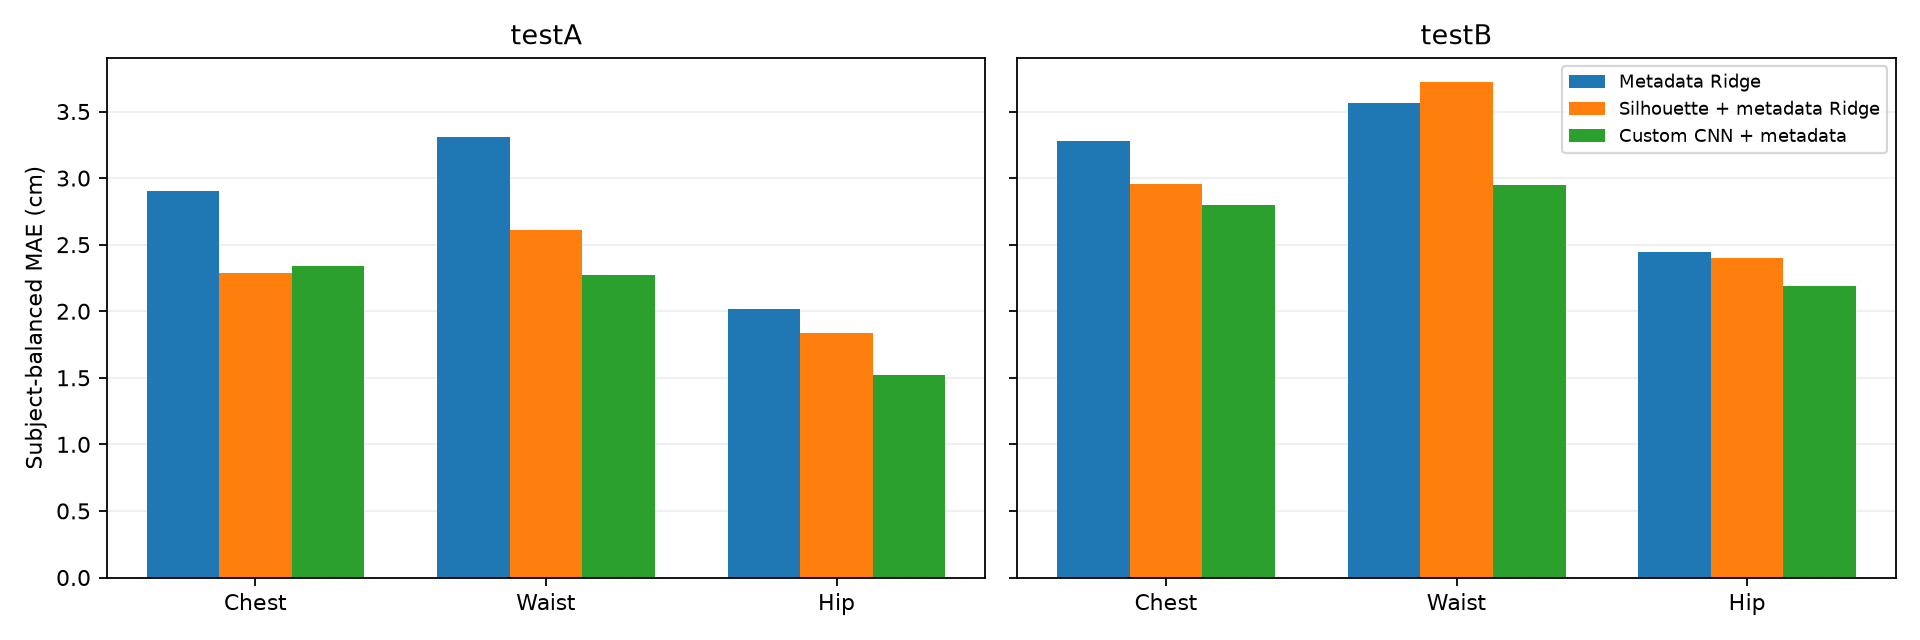

In [3]:
text = (OUTPUT/'report.md').read_text(encoding='utf-8')
text = text.replace('![Training history](training_history.png)', '')
text = text.replace('![Test comparison](mae_comparison.png)', '')
display(Markdown(text))
display(Image(filename=str(OUTPUT/'training_history.png')))
display(Image(filename=str(OUTPUT/'mae_comparison.png')))

## Dự đoán từ ảnh và checkpoint

Ví dụ một cặp ảnh trong testA. Truyền ảnh silhouette thật qua tiền xử lý và CNN đã lưu; không lấy dự đoán trực tiếp từ CSV. Dùng MAE toàn tập ở trên để đánh giá mô hình.

chest: true=97.74 cm, predicted=93.60 cm, error=4.15 cm
waist: true=80.65 cm, predicted=80.66 cm, error=0.01 cm
hip: true=98.07 cm, predicted=97.12 cm, error=0.95 cm


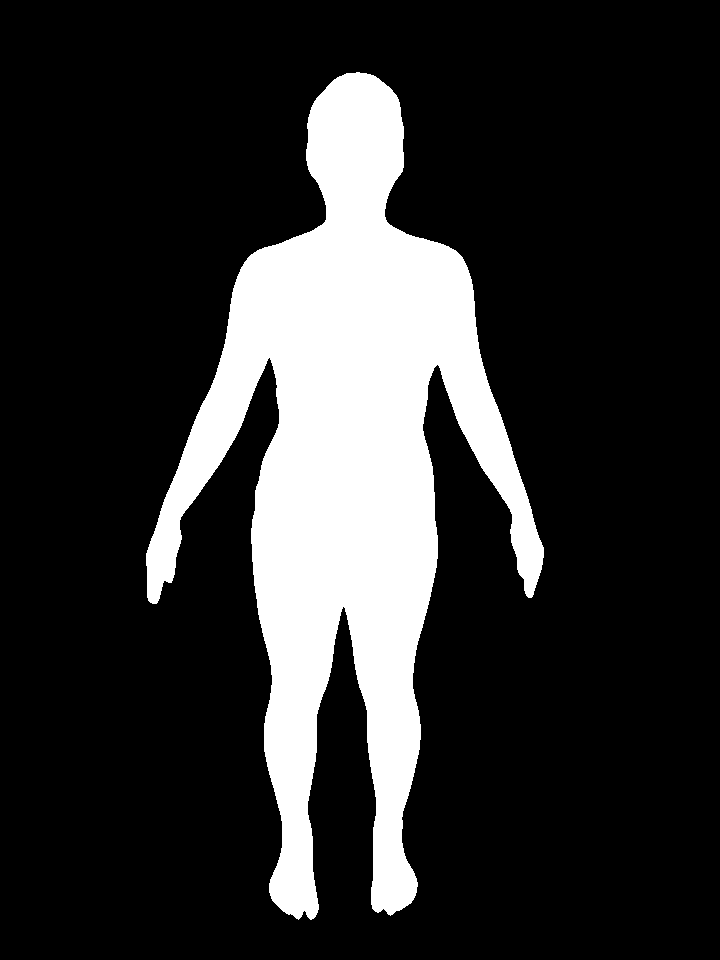

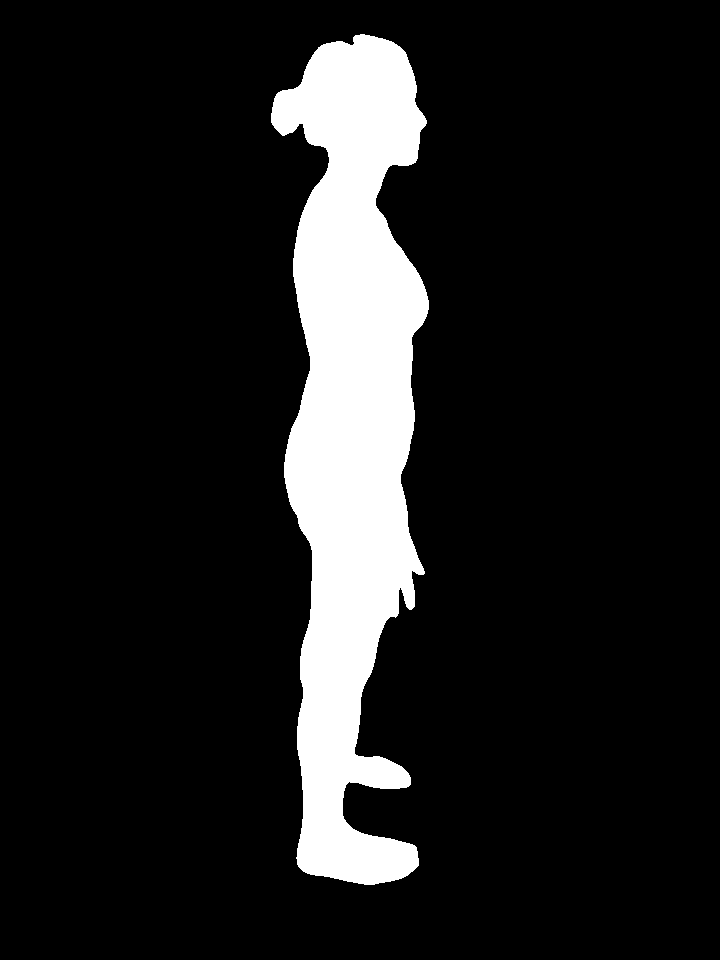

In [4]:
with np.load(ROOT/'data/processed/bodym/cnn_128x96_testA.npz') as data:
    photo_id = str(data['photo_ids'][0])
    known = data['metadata'][0].copy()
    truth = data['y'][0].copy()
front = ROOT/'data/raw/bodym/testA/mask'/(photo_id+'.png')
side = ROOT/'data/raw/bodym/testA/mask_left'/(photo_id+'.png')
prediction = predict_pair(ROOT/'models/bodym_cnn/model.pt', front, side,
                          float(known[0]), float(known[1]), 'male' if known[2] else 'female')
for target, actual in zip(('chest','waist','hip'), truth):
    estimated = prediction[target]
    print(f'{target}: true={actual:.2f} cm, predicted={estimated:.2f} cm, error={abs(actual-estimated):.2f} cm')
display(Image(filename=str(front), width=180))
display(Image(filename=str(side), width=180))

## Giới hạn của lần chạy

Đầu vào vẫn cần chiều cao, cân nặng và giới tính. Đây là một lần thử kiến trúc tự triển khai; kết quả có thể tốt hoặc kém Ridge tùy số đo và tập test. Hai tập test gốc có chung một ID người nên được báo cáo riêng. Không có nhãn tỷ lệ mỡ hoặc khối lượng cơ trong BodyM.